# 上下文与记忆：让 Agent 接得上对话，也记得住用户


## 多轮对话，为什么下一次就忘了？

上一章用中间件控制 Agent 的运行过程。本章继续解决一个更基础的问题：用户先说“我叫小明”，下一轮只问“我叫什么”，Agent 从哪里得到之前的信息？

**常见的模型 API 调用不会自动继承上一次请求的聊天历史。**模型根据本次收到的上下文生成回答；聊天应用表现出的“记得”，来自应用保存历史、检索资料，再把有关内容组织进本次请求。

记忆负责保存与取回信息，上下文工程负责决定当前任务需要哪些信息、以什么顺序呈现、占用多少上下文空间。保存了全部历史，不等于模型每次都看到了全部历史。

本篇按尚硅谷第 09 章《上下文与记忆》的 80 页课件整理，依次讨论短期记忆、消息治理、长期记忆和静态运行时上下文。重复日志压缩为关键输出与状态变化；有歧义的地方结合公开源码补充说明。

所有单元格都是 Markdown，代码放在带语言标识的代码围栏中，供阅读与复制。课程示例没有执行。


## 先分清三个位置：state、store、context

LangChain v1 的 Agent 构建在 LangGraph 上。上下文不是只有一串聊天消息，还包括过程状态、用户资料和本次运行的依赖。

| 位置 | 主要内容 | 是否随流程更新 | 范围与读法 |
| --- | --- | --- | --- |
| `state` | messages、当前任务、已收集参数等 | 可以通过状态更新改变 | 当前图状态；有 checkpointer 时可按线程恢复 |
| `store` | 用户偏好、资料、任务经验等 | 可以 put / delete | 按 namespace 与 key 组织，可跨线程读取 |
| `context` | 应用传入的用户标识、连接、配置等 | 按本次运行的固定依赖使用 | 本次 invoke / stream；通过 runtime.context 访问 |

例如“现在正在规划北京旅行”适合放 state；“用户偏好简短回答”适合放 store；“本次请求的登录用户是 user-1”适合由应用传入 context。

**运行时 context 不会自动转换成模型提示词。**工具或中间件读取之后，仍要选择把哪些内容交给模型。state 的自定义字段也不会仅因存在于字典中，就自动出现在模型消息里。


## 短期与长期，区别首先是作用范围

| 对比 | 短期记忆 | 长期记忆 |
| --- | --- | --- |
| 典型内容 | 某次对话历史、任务进度 | 用户资料、偏好、可复用经验 |
| 组织方式 | state + checkpointer + thread_id | store + namespace + key + value |
| 新建对话 | 新 thread_id 从另一份状态开始 | 同一用户命名空间仍可读取 |
| 进程重启后是否保留 | 取决于 checkpointer 后端 | 取决于 store 后端 |

“短期”并不等于“只存在内存”，数据库检查点也可以长期保存某个线程的短期记忆。“长期”也不等于“永不丢失”，InMemoryStore 在进程结束或重建实例后同样丢失内容。

更换 thread_id 只是切换状态空间，旧线程的数据并没有因此被删除；继续使用旧 ID，仍可能恢复旧状态。

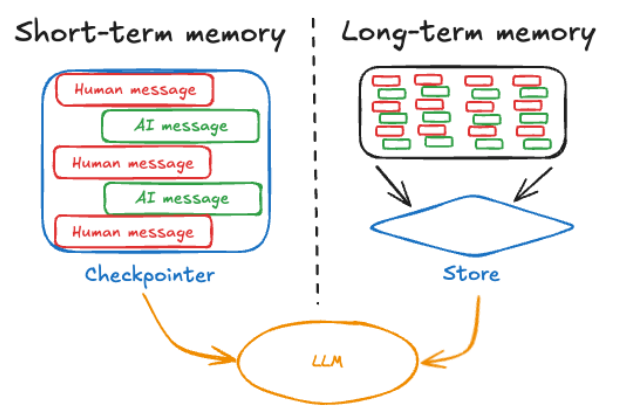

课件第 6 页：线程历史由 Checkpointer 支撑，跨会话资料由 Store 支撑。


## 本章公共模型配置

后面的示例沿用下面的 `model`。每个小案例可以单独阅读；跨小节复用的变量会明确说明。课程环境已经安装依赖时，沿用原来的锁定版本。

~~~dotenv
CLOSEAI_API_KEY=你的模型服务密钥
CLOSEAI_BASE_URL=服务商提供的OpenAI兼容API地址
CHAT_MODEL=账号可用的对话模型名称
SUMMARY_MODEL=账号可用的摘要模型名称
DATABASE_URL=postgresql://用户名:密码@数据库地址:5432/数据库名
~~~

~~~python
import os
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model

load_dotenv()

def make_chat_model(model_name: str):
    return init_chat_model(
        model=model_name,
        model_provider="openai",
        api_key=os.environ["CLOSEAI_API_KEY"],
        base_url=os.environ["CLOSEAI_BASE_URL"],
    )

model = make_chat_model(os.environ["CHAT_MODEL"])
~~~

需要工具调用、结构化输出或 embeddings 的案例，还要求模型服务支持相应能力。课件里的具体模型名、服务器 IP 和密码不作为这里的默认配置。


## 对照：没有 checkpointer 时，历史由调用方提供

~~~python
from langchain.agents import create_agent
from langchain.messages import HumanMessage

plain_agent = create_agent(model=model, tools=[])

first = plain_agent.invoke({"messages": [HumanMessage("你好，我叫小明")]})
second = plain_agent.invoke({"messages": [HumanMessage("我叫什么名字？")]})

print(second["messages"][-1].content)
~~~

第二次请求没有带姓名，也没有检查点恢复历史，Agent 没有可靠依据回答“小明”。即使偶然猜中，也不能算实现了记忆。

调用方手工管理历史时，可以把第一次返回的 messages 和新问题一起传入：

~~~python
history = first["messages"]
third = plain_agent.invoke({
    "messages": [*history, HumanMessage("我叫什么名字？")]
})
~~~

这种方式需要应用管理历史、隔离会话并限制长度。下面把这些线程状态交给 LangGraph 的检查点机制。


## 短期记忆的三个部件

**State 保存当前状态，Checkpointer 保存与加载检查点，Thread ID 决定读写哪个线程。**

~~~text
收到新问题 + thread_id
    ↓
加载该线程的检查点状态
    ↓
按字段的 reducer 合并新增输入
    ↓
执行 Agent：中间件 → 模型 → 工具 → 模型……
    ↓
在图运行的关键步骤保存检查点
~~~

检查点是图状态及恢复所需信息的快照，保存时机不只有“最终回答完成后”。Checkpointer 本身不负责调用模型，也不负责决定哪些历史适合交给模型。

`thread_id` 是对话标识，不是 Python 的操作系统线程号，也不是用户身份验证机制。同一用户可以拥有多个对话 ID。


## InMemorySaver：先把连续对话接起来

~~~python
from langchain.agents import create_agent
from langchain.messages import HumanMessage
from langgraph.checkpoint.memory import InMemorySaver

checkpointer = InMemorySaver()
chat_agent = create_agent(model=model, checkpointer=checkpointer)
config = {"configurable": {"thread_id": "chat-1"}}

questions = ["我叫张三", "我叫什么？", "我刚才问了什么问题？"]
for question in questions:
    response = chat_agent.invoke(
        {"messages": [HumanMessage(question)]},
        config=config,
    )
    print(response["messages"][-1].content)
~~~

三次调用复用同一个 checkpointer 和同一个 thread_id，每次只传新增消息。框架加载已有状态，再合并输入与回复。

预期能从历史回答“张三”和“我叫什么？”。实际措辞由模型生成，课件输出只是一次示例。

InMemorySaver 的数据保存在当前实例的进程内存中。不要在每次用户请求时重新创建它；相同字符串 ID 不能让一个全新的 Saver 找回另一个实例的数据。


## get_state：看到的是快照，不只是一段回答

~~~python
snapshot = chat_agent.get_state(config)

for message in snapshot.values.get("messages", []):
    print(message.type, message.content)

print("后续节点：", snapshot.next)
print("检查点配置：", snapshot.config)
~~~

| 信息 | 含义 |
| --- | --- |
| `values` | 当前快照里的状态字段，例如 messages |
| `next` | 下一步待运行的节点；正常完成时通常为空元组 |
| `config` | 该快照关联的线程、检查点标识等配置 |
| `metadata` | 图运行步骤、来源等信息 |
| `parent_config` | 上一个检查点的配置关系 |

messages 中也可能含工具调用、工具返回和消息 ID。无需把延迟、模型返回元信息和长串 UUID 全部复制成学习笔记。

快照展示的是此时保存的状态；中间件可能在调用模型时另行过滤消息，所以它不一定等于某次模型请求的原样输入。


## 同一用户，也可以有多个独立线程

~~~python
new_config = {"configurable": {"thread_id": "chat-2"}}

chat_agent.invoke(
    {"messages": [HumanMessage("我叫什么名字？")]},
    config=new_config,
)

# 回到 chat-1，继续使用原来的历史。
chat_agent.invoke(
    {"messages": [HumanMessage("请复述我刚开始告诉你的姓名")]},
    config=config,
)
~~~

chat-2 没有 chat-1 的聊天记录；回到 chat-1 可以读取它仍然保存的状态。后面通过 Store 共享用户资料，才会让不同对话都能查到同一份姓名。

应用通常维护“用户 → 可访问的会话 ID”的关系。不能允许客户端随意填写别人的 thread_id 就读取对方聊天。线程划分提供数据组织方式，访问控制由应用实现。


## messages 为什么能自动追加？

AgentState 的 messages 字段使用 `add_messages` reducer。新输入不是简单地把整个列表覆盖掉，而是按消息 ID 合并。

| 更新内容 | 对当前 messages 的影响 |
| --- | --- |
| 一条新的消息 ID | 追加消息 |
| 与已有消息相同的 ID | 更新相应消息 |
| `RemoveMessage(id=已有ID)` | 从合并后的当前列表移除该消息 |
| `RemoveMessage(id=REMOVE_ALL_MESSAGES)` | 清空此前列表，再接上本次更新中后续的消息 |

普通消息没有 ID 时，框架会在合并过程中补充 ID。重复传入已经保存的历史，如果 ID 没有保留或重新生成，就可能再次追加同样的内容。

所以接入 checkpointer 后，一般只传本轮新增消息；不要同时再手工拼接一遍完整历史。自定义 state 字段是否追加，取决于该字段自己的 reducer。


## 开新对话、清空当前消息、删除线程，是三件事

| 目的 | 做法 | 数据结果 |
| --- | --- | --- |
| 从空对话开始 | 使用新的 thread_id | 旧线程仍保存 |
| 重置当前线程的 messages | 用 REMOVE_ALL_MESSAGES 更新状态 | 旧检查点仍可能保存原消息，其他 state 字段也可能保留 |
| 删除该线程的检查点记录 | 使用后端支持的线程删除 API | 删除该后端中相应线程的检查点与写入记录 |

下面只是 API 阅读示例，目标 ID 使用占位名称：

~~~python
from langchain.messages import RemoveMessage
from langgraph.graph.message import REMOVE_ALL_MESSAGES

target_config = {"configurable": {"thread_id": "需要重置的线程ID"}}
chat_agent.update_state(
    target_config,
    {"messages": [RemoveMessage(id=REMOVE_ALL_MESSAGES)]},
)

# 当前公开的 InMemorySaver 实现提供此方法。
checkpointer.delete_thread("需要删除的线程ID")
~~~

课件第 14 页“没有删除 API”的说明不能直接用于当前版本。使用前核对已安装后端与版本；删线程也不会自动删掉长期 Store、业务日志或其他存储里的用户资料。


## PostgreSQL：让线程状态越过进程重启

课件选择 PostgreSQL 保存检查点。数据库需事先创建，连接串通过环境变量提供。已有课程依赖时沿用原版本；缺少对应后端包时再补充：

~~~bash
pip install langgraph-checkpoint-postgres
~~~

`PostgresSaver` 保存短期线程状态；`PostgresStore` 保存后面的跨线程记忆。它们可以使用同一数据库，但接口、表结构与职责不同。

连接串的用户、密码、数据库名与连接选项按实际环境配置。课件中的 `sslmode=disable` 是演示设置，不是所有部署环境的通用选项。


## PostgresSaver：首次写入与再次恢复

~~~python
import os
from langchain.agents import create_agent
from langchain.messages import HumanMessage
from langgraph.checkpoint.postgres import PostgresSaver

db_url = os.environ["DATABASE_URL"]
db_config = {"configurable": {"thread_id": "postgres-demo-1"}}

with PostgresSaver.from_conn_string(db_url) as saver:
    saver.setup()
    db_agent = create_agent(model=model, checkpointer=saver)
    response = db_agent.invoke(
        {"messages": [HumanMessage("你好，我是老王")]},
        config=db_config,
    )
    print(response["messages"][-1].content)
~~~

`setup()` 创建后端所需表，并执行必要的版本迁移。它不是清空数据库；初始化新环境时要调用，生产环境通常统一管理迁移。

第二次运行重新建立连接、创建 Agent，使用同一数据库和线程 ID：

~~~python
with PostgresSaver.from_conn_string(db_url) as saver:
    db_agent = create_agent(model=model, checkpointer=saver)
    response = db_agent.invoke(
        {"messages": [HumanMessage("你还记得我是谁吗？")]},
        config=db_config,
    )
    print(response["messages"][-1].content)
~~~

Agent 使用数据库中的检查点恢复历史，预期可以回答“老王”。两个代码段都让调用发生在 `with` 内；离开连接生命周期后，不应继续调用绑定该连接的 Agent。

这里第二段假定数据库已经完成 setup，且数据没有被删除。相同 thread_id 还要对应相同的存储位置和兼容的状态结构，才能恢复。


## 数据库里保存的不是单纯一张聊天表

PostgreSQL 的逻辑层次是 Database → Schema → Table。Schema 是命名空间，不等同于分区表。

在 psql 中可以查看：

~~~text
\l
\dn
SELECT current_schema();
\dt
~~~

| 课件中的表 | 主要作用 |
| --- | --- |
| checkpoints | 线程的检查点及相关元数据 |
| checkpoint_blobs | 拆开保存的 channel 值等内容 |
| checkpoint_writes | 中间写入与 pending writes |
| checkpoint_migrations | 记录后端迁移版本 |

这些是框架的内部持久化表，具体结构会随版本演进。应用读取状态优先使用 get_state 等接口，而不是自己拼接内部表来重建消息。

可以保留聊天审计表作为业务数据，但它与图恢复所需的检查点不是同一种数据。


## 为什么重新运行内存例子，总像第一次见面？

| 情况 | 同一 thread_id 能否接上历史 |
| --- | --- |
| 同一进程、复用同一个 InMemorySaver | 能 |
| 同一进程、每次创建新的 InMemorySaver | 不能从旧实例恢复 |
| 进程重启、使用 InMemorySaver | 不能 |
| 新建 PostgresSaver，连接同一持久化数据库 | 数据仍在且状态兼容时能 |

重新创建 Agent 不一定丢记忆，关键是它绑定的存储。重新创建内存 Saver 才会切换到一份空存储；复用旧 Saver 的新 Agent 仍可能加载原线程。

课件对比的“多次运行”指重新运行包含 Saver 初始化的整段程序。一次运行内的多次 invoke 仍会正常累积历史。


## 历史越来越长，需要管理什么？

历史持续追加会增加 token 消耗、延迟和存储量，也可能超过模型上下文窗口。即使能放下全部内容，旧话题和重复工具结果也可能干扰当前判断。

| 策略 | 主要收益 | 代价 |
| --- | --- | --- |
| 裁剪 | 保留近期内容，控制请求长度 | 较早细节可能丢失 |
| 删除 | 从当前状态移除明确不需要的消息 | 后续不能从当前列表读取被删内容 |
| 摘要 | 压缩旧历史的语义，保留近期原文 | 增加摘要调用，可能漏掉或改变细节 |
| 自定义过滤 | 依业务筛掉无关信息 | 需维护选择规则及消息完整性 |

判断一个策略是否改变记忆，不能只看它发生在 before_model 还是 after_model。**返回 state 更新会改变状态；request.override 改的是本次调用请求。**

系统提示、工具定义、检索材料和模型输出也占上下文空间。只给 messages 设置一个长度阈值，不能保证完整请求一定装得下。


## 课件裁剪示例：保留首条与最近消息

下面保留课件算法，便于对照后面的状态变化。它适用于观察普通 Human / AI 对话，不适合作为带工具调用场景的通用裁剪策略。

~~~python
from typing import Any
from langchain.agents import AgentState, create_agent
from langchain.agents.middleware import before_model
from langchain.messages import RemoveMessage
from langgraph.graph.message import REMOVE_ALL_MESSAGES
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.runtime import Runtime

@before_model
def course_trim(state: AgentState, runtime: Runtime) -> dict[str, Any] | None:
    messages = state["messages"]
    if len(messages) <= 3:
        return None

    first = messages[0]
    recent = messages[-3:] if len(messages) % 2 == 0 else messages[-4:]
    return {
        "messages": [RemoveMessage(id=REMOVE_ALL_MESSAGES), first, *recent]
    }

trim_agent = create_agent(
    model=model,
    middleware=[course_trim],
    checkpointer=InMemorySaver(),
)
trim_config = {"configurable": {"thread_id": "trim-demo-1"}}

for text in ["你好，我是老王", "从现在起，你叫小王", "今天天气不错",
             "告诉我，你是谁？我是谁？"]:
    result = trim_agent.invoke(
        {"messages": [{"role": "user", "content": text}]},
        config=trim_config,
    )
~~~

返回值包含“清空旧列表，再写入保留消息”的状态更新，因此裁剪后的消息会进入后续检查点。这段代码并不是只缩短本次模型请求。第一条消息也只是首条历史，并不必然是 SystemMessage。


## 用消息序列，看清哪里被剪掉了

记 `H1` 为“我是老王”，`H2` 为“你叫小王”，`H3` 为天气闲聊，`H4` 为最后的身份提问；`Ai` 是相应回复。假设每轮只有一条用户消息与一条最终回答。

| 模型调用前 | 裁剪前的列表 | 裁剪后的列表 |
| --- | --- | --- |
| 第一轮 | H1 | H1 |
| 第二轮 | H1, A1, H2 | H1, A1, H2 |
| 第三轮 | H1, A1, H2, A2, H3 | H1 + A1, H2, A2, H3；没有缩短 |
| 第四轮 | H1, A1, H2, A2, H3, A3, H4 | H1 + A2, H3, A3, H4 |

第四轮删除了 H2，保留了可能转述 H2 的 A2。因此模型仍可能从 A2 推断“你叫小王”。实际回答取决于保留消息的内容，不能根据丢了一条消息就断言模型一定忘了某个事实。

### 为什么奇偶数不是可靠规则？

一次工具调用会增加 AIMessage 和 ToolMessage，模型还可能继续调用多个工具，消息不再严格两两对应。切片可能只留下工具结果，丢掉它对应的调用，也可能让历史从孤立的 AI 回复开始。

正式策略应按完整对话轮次或完整工具交互组织，再结合 token 预算裁剪；工具调用请求与对应的结果必须保持协议要求的关系。


## 只裁剪本次请求，可以使用包装钩子

如果希望保留线程中的完整历史，而只缩短交给模型的列表，可以修改 ModelRequest：

~~~python
from langchain.agents.middleware import wrap_model_call, ModelRequest
from langchain.messages import trim_messages
from langchain_core.messages.utils import count_tokens_approximately

@wrap_model_call
def trim_request(request: ModelRequest, handler):
    selected = trim_messages(
        request.messages,
        max_tokens=2000,
        token_counter=count_tokens_approximately,
        strategy="last",
        start_on="human",
        end_on=("human", "tool"),
        include_system=True,
        allow_partial=False,
    )
    return handler(request.override(messages=selected))

request_trim_agent = create_agent(
    model=model,
    middleware=[trim_request],
    checkpointer=InMemorySaver(),
)
~~~

这里没有返回删除消息的 state 更新，线程历史仍按原流程保存。`2000` 是示例消息预算，token_counter 是近似计数；应给系统提示、工具和输出留出余量。

`start_on`、`end_on` 和 `include_system` 帮助选择消息边界，但不能代替对复杂工具序列的验证。此例也不限制检查点存储量：请求变短与后端清理是两个问题。


## 消息删除：after_model 保留最后五条

课件另一个例子在模型回复之后删除旧消息：

~~~python
from langchain.agents.middleware import after_model

@after_model
def delete_old_messages(state: AgentState, runtime: Runtime) -> dict | None:
    messages = state["messages"]
    if len(messages) <= 5:
        return None
    excess = len(messages) - 5
    return {
        "messages": [RemoveMessage(id=m.id) for m in messages[:excess]]
    }

delete_agent = create_agent(
    model=model,
    middleware=[delete_old_messages],
    checkpointer=InMemorySaver(),
)
delete_config = {"configurable": {"thread_id": "delete-demo-1"}}

for text in ["你好，我是老王", "从现在起，你叫小王", "今天天气不错",
             "告诉我，你是谁？我是谁？"]:
    response = delete_agent.invoke(
        {"messages": [{"role": "user", "content": text}]},
        config=delete_config,
    )
~~~

after_model 在每次模型调用后执行；有工具循环时，一轮 invoke 可能触发多次。这种按条数硬删的教学例子同样可能破坏工具调用关系，实际使用需改成按完整交互删除。

它不会降低刚刚结束那次模型调用的输入成本，作用主要体现为更新后续状态。


## 删除后的数量，要以当前状态重新计算

在没有工具、每轮新增一条 Human 与一条 AI 的前提下：

| 轮次 | 回复前消息数 | 回复后消息数 | 删除数 | 最终状态 |
| --- | --- | --- | --- | --- |
| 第一轮 | 1 | 2 | 0 | H1, A1 |
| 第二轮 | 3 | 4 | 0 | H1, A1, H2, A2 |
| 第三轮 | 5 | 6 | 1 | A1, H2, A2, H3, A3 |
| 第四轮 | 6 | 7 | 2 | A2, H3, A3, H4, A4 |

课件第四轮按累计产生了八条消息计算“删三条”，但 H1 在第三轮已经从当前状态移除。第四轮实际是五条历史 + H4 + A4，共七条，删除两条。

被删原句也可能已经被别的回复转述，删除一条消息不一定就删除了对应事实。若需要真正清理某类信息，还要检查摘要、其他消息、长期 Store 及旧检查点。


## RemoveMessage 在 reducer 合并时生效

`RemoveMessage` 是状态更新指令。对于默认的 add_messages reducer，框架在合并状态时按 ID 移除目标消息，并返回新的当前消息列表。

~~~text
当前状态：[Message(id="1"), Message(id="2")]
更新指令：[RemoveMessage(id="1")]
合并结果：[Message(id="2")]
~~~

因此，不应把它解释成“当前消息列表一直追加墓碑，等下一次模型调用时才临时隐藏”。删除后读取当前 messages，就已看不到该消息；删除不存在的消息 ID 还可能抛错。

**从当前 state 删除，与从持久化历史彻底擦除不是同一件事。**检查点系统可以保留删除前的快照。要减少后端历史占用或处理真正的遗忘需求，需使用存储后端的清理机制。


## 摘要：留下语义，缩短旧历史

裁剪直接舍弃旧内容；摘要先提炼关键事实，再用“摘要 + 近期原文”替换当前历史。它适合长对话中仍要保留早期需求、结论和用户背景的场景。

摘要是有损压缩。名字、数值、待办事项和否定条件都可能丢失或被改写，关键业务事实应单独保存为结构化数据。

摘要中间件修改当前消息状态，后续检查点保存的是摘要与保留片段。它不会自动删掉旧检查点，也不等于向长期 Store 写入用户资料。

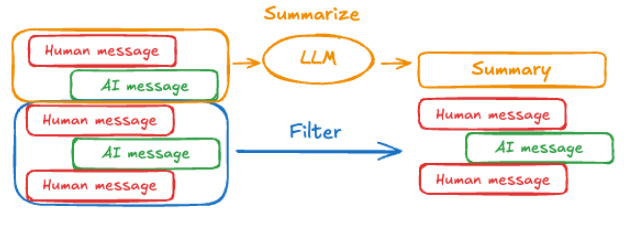

课件第 30 页：旧消息生成摘要，近期消息保留原文，两部分合成新上下文。


## SummarizationMiddleware：触发条件与保留规则

~~~python
from langchain.agents.middleware import SummarizationMiddleware

summary_model = make_chat_model(os.environ["SUMMARY_MODEL"])
summary_agent = create_agent(
    model=model,
    checkpointer=InMemorySaver(),
    middleware=[
        SummarizationMiddleware(
            model=summary_model,
            trigger=("tokens", 100),
            keep=("messages", 2),
            summary_prompt=(
                "请压缩以下历史，保留用户自报的姓名、职业、偏好、已确认事实与未完成任务。"
                "区分用户陈述与助手推测，不补充不存在的信息。\n{messages}"
            ),
        )
    ],
)
summary_config = {"configurable": {"thread_id": "summary-demo-1"}}

for text in ["我叫张三，是工程师。重复的闲聊内容。" * 20, "请总结我的信息"]:
    response = summary_agent.invoke(
        {"messages": [{"role": "user", "content": text}]},
        config=summary_config,
    )

for message in summary_agent.get_state(summary_config).values["messages"]:
    print(message.type, message.content)
~~~

100 tokens 与保留两条消息是课件为了容易观察而设置的演示值。`summary_prompt` 中的 `{messages}` 是历史文本的占位符。

### 达到阈值，不等于一定立刻缩短

中间件还要找出可摘要的旧片段。如果消息很少、全部都属于保留区，可能没有可压缩的前缀。保留边界还需兼顾工具调用完整性。

`trigger` 决定何时尝试摘要，`keep` 决定保留多少近期上下文。它们不保证新历史恰好变成 100 tokens；摘要、近期消息和其他请求内容仍可能超过这个数。


## 摘要阈值怎样设置？

先确认实际模型的上下文上限，再给系统提示、工具定义、检索结果和输出预留空间。短期内可以按 token 阈值设置，后续根据真实流量调整。

| 观察现象 | 优先检查 |
| --- | --- |
| 几乎每轮都摘要 | 阈值是否过低，摘要是否太长，保留区是否太大 |
| 摘要从不触发 | 计数方式、阈值、是否根本没有可压缩的旧历史 |
| 摘要后仍超长 | 最新消息本身是否巨大，工具结果是否过多 |
| 关键事实被遗忘 | 摘要提示与质量；是否应另存结构化资料 |
| 费用没有降低 | 摘要次数、摘要模型费用与节省的后续输入费用 |

便宜的摘要模型可能减少成本，但结果还要足够可靠。课件“上下文窗口的约四分之三”只是粗略示例，不能替代完整请求预算。

自定义过滤也适用同一原则：明确取舍规则，并核对消息角色、工具调用对应关系和重要信息。


## AgentState：不止 messages

课件列出三个核心字段，理解用途比背完整源码更重要。

| 字段 | 含义 | 读取注意点 |
| --- | --- | --- |
| messages | 当前合并后的消息记录 | 使用 add_messages reducer |
| jump_to | 中间件要求的流程跳转 | 内部临时控制字段，不是用户资料 |
| structured_response | 结构化输出结果 | 只有相关流程生成后才存在 |

AgentState 是 TypedDict 类型定义，实际状态按照字典方式访问。`NotRequired` 表示这个键允许不存在，并不表示值必然是 None；值是否允许 None，要看字段自身的类型。

~~~python
messages = response["messages"]
structured = response.get("structured_response")
~~~

默认结构不是字段数量永远固定为三。中间件和自定义 state_schema 都可以扩展状态，例如用户标识、任务槽位和计数器。


## 用天气案例观察 jump_to 与结构化输出

这个例子连接上一章的中间件与第 06 章结构化输出。工具返回固定模拟数据，只用于理解状态。

~~~python
from uuid import uuid4
from pydantic import BaseModel, Field
from langchain.agents import create_agent, AgentState
from langchain.agents.middleware import before_model, after_agent
from langchain.agents.structured_output import ToolStrategy
from langchain.messages import HumanMessage, AIMessage
from langchain.tools import tool
from langgraph.runtime import Runtime

class WeatherInfo(BaseModel):
    city: str = Field(description="城市名称")
    temperature: str = Field(description="气温")
    desc: str = Field(description="天气概述与来源")

@tool
def get_weather(city: str) -> dict:
    """返回指定城市的固定模拟天气，供框架教学演示。"""
    return {"city": city, "temperature": "9~16℃",
            "desc": "模拟数据：晴朗，适合外出"}

@before_model(can_jump_to=["tools"])
def direct_tool_call(state: AgentState, runtime: Runtime) -> dict | None:
    last = state["messages"][-1]
    if isinstance(last, HumanMessage) and isinstance(last.content, str):
        if "北京" in last.content and "天气" in last.content:
            return {
                "messages": [AIMessage(content="", tool_calls=[{
                    "name": "get_weather", "args": {"city": "北京"},
                    "id": f"direct-{uuid4()}", "type": "tool_call",
                }])],
                "jump_to": "tools",
            }
    return None

@after_agent
def show_final_state(state: AgentState, runtime: Runtime) -> None:
    print("最终结构化结果：", state.get("structured_response"))

weather_agent = create_agent(
    model=model,
    tools=[get_weather],
    middleware=[direct_tool_call, show_final_state],
    response_format=ToolStrategy(WeatherInfo),
    system_prompt="整理工具提供的天气，注明是模拟数据。",
)
weather_result = weather_agent.invoke({
    "messages": [HumanMessage("请查询北京天气")]
})
~~~

应用构造 AIMessage 工具请求并跳到 tools，工具返回之后仍由模型生成最终结构化结果。这里绕过的是第一次选工具的模型判断，整个 invoke 仍会使用模型。

`jump_to` 是流程控制信息，正常不作为最终用户输出；`structured_response` 是已经解析好的 WeatherInfo。模型必须支持所用的工具调用与结构化输出方式。


## 长期记忆：把资料从某次聊天中抽出来

一段对话可以结束，但“偏好中文”“喜欢 Python”“常用简短回答”仍可能对下次任务有用。这类数据按用户、组织或应用范围保存，使用时再读取到当前流程。

| 类型 | 记住什么 | 例子 |
| --- | --- | --- |
| Semantic，语义记忆 | 事实、概念与偏好 | 用户偏好中文和简洁风格 |
| Episodic，情景记忆 | 过去执行过程与经验 | 一个成功任务的输入、步骤、结果；可用于 few-shot |
| Procedural，程序性记忆 | 工作规则与方法 | 系统提示、处理流程、工具使用规则 |

这三类是内容分类，不是三个必须分别实例化的 Memory 类。“语义记忆”也不等同于“向量检索”：用户资料可以直接按键读取，无需 embedding。

长期信息可跨线程使用，但读取仍受应用定义的命名空间和权限约束，不是所有用户自动共享全部资料。


## Store → Namespace → Key → Value

Store 是仓库接口；Namespace 用字符串元组分组；Key 标识一条记录；Value 是 JSON-like 字典。

~~~python
from langgraph.store.memory import InMemoryStore

profile_store = InMemoryStore()
namespace = ("users", "user-1", "preferences")
profile_store.put(namespace, "profile", {
    "language": "zh-CN",
    "style": "short_direct",
    "likes": ["python", "rag"],
})
~~~

~~~text
同一用户 user-1
├─ thread chat-1 → 一份聊天 state
├─ thread chat-2 → 另一份聊天 state
└─ Store
   └─ ("users", "user-1", "preferences")
      ├─ key="profile" → 偏好
      └─ key="writing_style" → 写作风格
~~~

相同 namespace 下 key 唯一；不同 namespace 可以有相同 key。`("users",)` 是一元素元组，需要尾部逗号，`("users")` 仍是字符串。

命名空间里包含 thread_id，会让那类数据按线程分组；想跨会话共享用户资料，就不要把资料的唯一定位绑定为某个对话 ID。


## put / get：写的是字典，读到的是 Item

~~~python
ns = ("users", "user-1", "profile")
profile_store.put(ns, "basic", {"name": "小蓝", "city": "上海"})

item = profile_store.get(ns, "basic")
if item is not None:
    print(item.value)
    print(item.key, item.namespace, item.created_at, item.updated_at)

missing = profile_store.get(ns, "missing-key")
print(missing)  # 找不到时返回 None。
~~~

`get(namespace, key)` 精确读取记录，返回 Item 或 None。Item 包含 value，也包含键、路径和时间等元信息；不能把它当作 value 字典直接索引。

再次对同一 namespace + key 执行 put，写入的是新 value，不会自动深度合并资料：

~~~python
old = profile_store.get(ns, "basic")
new_value = {**(old.value if old else {}), "name": "小红"}
profile_store.put(ns, "basic", new_value)
~~~

这段代码显式保留 city。直接 put `{"name": "小红"}` 则可能覆盖整条 value，把 city 一并丢掉。列表、嵌套字典和多请求并发还需要自己的合并策略。


## created_at 与 updated_at，后端实现可能不同

课件观察了更新同一记录之后的时间字段：

| 实现 | 当前公开实现中的行为 |
| --- | --- |
| InMemoryStore | put 重新构造 Item，创建时间与更新时间都重设 |
| PostgresStore | 同键冲突时更新 value 和 updated_at，通常保留 created_at |

两个时间很接近不代表每次严格相等，内存实现可以分别取时间。不要把内存演示的时间细节当成所有后端统一保证。

需要稳定业务创建时间时，可在自己的 value 中保存明确字段；要审计每次修改，则使用业务事件记录，而不是只依赖最后更新时间。


## PostgresStore：把跨会话资料存入数据库

~~~python
from langgraph.store.postgres import PostgresStore

user_ns = ("users", "user-11", "profile")
with PostgresStore.from_conn_string(os.environ["DATABASE_URL"]) as store:
    store.setup()
    store.put(user_ns, "basic", {"name": "小蓝"})
    print(store.get(user_ns, "basic").value)

# 重新连接同一数据库，仍可读取之前写入的记录。
with PostgresStore.from_conn_string(os.environ["DATABASE_URL"]) as store:
    old = store.get(user_ns, "basic")
    if old is not None:
        store.put(user_ns, "basic", {**old.value, "name": "小红"})
~~~

Store 与 Saver 各有自己的 setup。课件无语义索引时主要新增 store、store_migrations；配置向量索引时还会有对应向量相关结构及依赖。

数据库持久化解决进程重启的问题，但不会自动提取记忆、自动决定更新规则或自动把资料塞进模型上下文。


## search：前缀、过滤与语义相似度

| 参数 | 作用 |
| --- | --- |
| namespace_prefix | 字符串元组，限制搜索所在的命名空间前缀 |
| query | 自然语言语义查询，需要配置 embedding 索引 |
| filter | 按 value 中的字段筛选 |
| limit / offset | 最大返回条数与跳过条数 |
| refresh_ttl | 支持 TTL 的后端中，控制是否刷新有效期 |

返回值是 SearchItem 列表，除了 Item 的字段还有 score 等检索信息。普通字段过滤的 score 可能为 None；向量相似度分数不是事实正确率。

`put` 的 index 参数控制是否及对哪些字段建立索引：None 沿用 Store 默认索引配置，False 跳过该条的语义索引，字段路径列表则指定本条的索引内容。没有初始化 embedding 索引时，不能仅靠传 query 或 index 获得语义检索。

TTL 是否支持由具体后端决定。当前 BaseStore 的 TTL 约定单位是分钟，refresh_ttl 的默认行为随 Store 配置；不要假定所有实现都支持自动过期。


## 准备课件里的三份偏好数据

下面这些是演示资料，后面的前缀与 filter 示例复用 `preference_store` 和 `preferences`。

~~~python
from langgraph.store.memory import InMemoryStore

preferences = {
    "Alice": {"course": "计算机组成原理", "sports": "跑步",
              "food": "紫光园奶皮子酸奶"},
    "Bob": {"course": "数字电路与模拟电路", "sports": "跑步",
            "food": "奶皮子糖葫芦"},
    "Black": {"course": "数字电路与模拟电路", "sports": "羽毛球",
              "food": "紫光园奶皮子酸奶"},
}
preference_store = InMemoryStore()
for name, value in preferences.items():
    preference_store.put(("users", name, "memories"), "preferences", value)
~~~

同一个 preferences key 位于三个不同的用户命名空间，不会互相覆盖。这里不配置 index，直接展示结构化检索。


## 前缀扩大范围，filter 再筛字段

~~~python
all_users = preference_store.search(("users",))
alice = preference_store.search(("users", "Alice"))
yogurt = preference_store.search(
    ("users",), filter={"food": "紫光园奶皮子酸奶"}
)
runners = preference_store.search(("users",), filter={"sports": "跑步"})
circuits = preference_store.search(
    ("users",), filter={"course": "数字电路与模拟电路"}
)

for item in runners:
    print(item.namespace, item.value)
~~~

| 查询条件 | 演示数据的匹配者 |
| --- | --- |
| 前缀 users | Alice、Bob、Black |
| 前缀 users / Alice | Alice |
| food 是指定酸奶 | Alice、Black |
| sports 是跑步 | Alice、Bob |
| course 是数电模电的完整字段值 | Bob、Black |

这是字段匹配，不会自动把“数电模电”理解成“数字电路与模拟电路”。同义表达需要后面的语义索引。

广泛前缀检索适合有权限的管理场景。实际为单个用户读取记忆时，通常把搜索前缀限定到该用户。


## 自定义 embedding：先看清索引的形状

~~~python
def constant_embed(texts: list[str]) -> list[list[float]]:
    return [[1.0] * 6 for _ in texts]

debug_store = InMemoryStore(index={
    "embed": constant_embed,
    "dims": 6,
    "fields": ["$", "course"],
})
debug_store.put(("users", "Alice", "memories"), "preferences",
                preferences["Alice"])
~~~

这个函数把所有文本映射成相同的六维向量，只能观察嵌入接口和索引组织方式，无法判断“数电模电”与哪门课程更相关。

| fields 路径 | 嵌入的内容 |
| --- | --- |
| `$` | value 的整体 JSON 内容 |
| `course` | 一级 course 字段 |
| `profile.summary` | 嵌套对象中的 summary |
| `memories[*].text` | 数组各元素中的 text |

一个 item 可对应多个字段向量，数组路径也可能提取多段文本。模型输出向量的维度必须与 dims 一致。

课件用 `_vectors` 观察内部数据，这属于私有实现，只适合调试：

~~~python
vector = debug_store._vectors[("users", "Alice", "memories")]["preferences"]["course"]
print(vector)  # 示意：[1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
~~~

业务代码应依赖 put / get / search 等公开接口，不依赖私有字典的结构。


## 真正的语义检索，需要有区分度的嵌入模型

下面沿用课件的 text-embedding-3-large 示例。服务要支持该模型；默认输出为 3072 维，若使用其他模型或主动缩小维度，应同步修改 dims。

~~~python
from langchain.embeddings import init_embeddings

embedding_model = init_embeddings(
    model="openai:text-embedding-3-large",
    api_key=os.environ["CLOSEAI_API_KEY"],
    base_url=os.environ["CLOSEAI_BASE_URL"],
)
semantic_store = InMemoryStore(index={
    "embed": embedding_model,
    "dims": 3072,
    "fields": ["$"],
})
for name, value in preferences.items():
    semantic_store.put(("users", name, "memories"), "preferences", value)

matches = semantic_store.search(("users",), query="数电模电", limit=2)
for item in matches:
    print(item.namespace, item.score, item.value)
~~~

put 时建立索引，search 时把 query 转成向量，并在候选中按相似度排序。此例预期 Bob 和 Black 更相关；具体分数与顺序随模型和数据变化。

query 可以和 filter 同时使用。`limit=2` 只限制返回前两条，不意味着两条都足够相关；默认 limit 是 10，也不是自动返回全部符合前缀的数据。

有 Store 并不必须有向量数据库。按 key 读用户资料只需键值存储；只有需要语义搜索时，才配置 embedding 与相应索引。


## 在 Agent 内部，从哪里取得 Store？

创建 Agent 时传 `store=...`，框架把它放到运行时对象里。

| 位置 | Store 访问路径 | 静态上下文路径 |
| --- | --- | --- |
| 工具 | runtime.store | runtime.context |
| before_model / after_model 等节点钩子 | runtime.store | runtime.context |
| wrap_model_call | request.runtime.store | request.runtime.context |
| wrap_tool_call | request.runtime.store | request.runtime.context |
| dynamic_prompt | request.runtime.store | request.runtime.context |

工具的 ToolRuntime 还包含 state、config、tool_call_id、stream_writer 等信息。runtime 参数由框架注入，不让模型自行填写。

Store 可能为 None，读取的记录也可能不存在。示例应检查这些情况，再访问 `.value`；课件里的直接链式取值依赖“记录已经预置”的前提。


## 课件方案：工具从自定义 state 取 user_id

这里先保留课件思路：state_schema 扩展用户 ID，工具通过 runtime.state 定位资料。

~~~python
from typing import Any, NotRequired
from langchain.agents import AgentState, create_agent
from langchain.tools import tool, ToolRuntime

class UserState(AgentState):
    user_id: NotRequired[str]

user_store = InMemoryStore()

def state_user_id(runtime: ToolRuntime[Any, UserState]) -> str:
    user_id = runtime.state.get("user_id")
    if not user_id:
        raise ValueError("应用没有提供 user_id")
    return user_id

@tool
def save_user_info(name: str, runtime: ToolRuntime[Any, UserState]) -> str:
    """保存当前用户自报的姓名。"""
    if runtime.store is None:
        raise RuntimeError("Agent 没有配置 Store")
    ns = ("users", state_user_id(runtime), "profile")
    runtime.store.put(ns, "basic", {"name": name})
    return "saved"

@tool
def get_user_info(runtime: ToolRuntime[Any, UserState]) -> dict:
    """读取当前用户已记录的资料。"""
    if runtime.store is None:
        raise RuntimeError("Agent 没有配置 Store")
    ns = ("users", state_user_id(runtime), "profile")
    item = runtime.store.get(ns, "basic")
    return item.value if item else {"status": "unknown"}

user_agent = create_agent(
    model=model,
    tools=[save_user_info, get_user_info],
    state_schema=UserState,
    store=user_store,
    system_prompt="用户提供姓名时用工具保存；询问身份时先用工具读取。",
)
user_agent.invoke({"messages": [{"role": "user", "content": "你好，我是小花"}],
                   "user_id": "user-1"})
user_agent.invoke({"messages": [{"role": "user", "content": "我是谁？"}],
                   "user_id": "user-1"})
~~~

这里没有 checkpointer，两次调用不会自动继承 messages，却复用同一个 user_store。第二次可以通过工具查到第一次写入的姓名。

系统提示引导模型使用工具，实际是否写入要看工具调用与 Store 回执。用户 ID 应由应用提供，不能把聊天中的自报身份当作访问别人的资料的凭据。


## 同一套工具，也可以换成数据库 Store

复用上面的 UserState、save_user_info 与 get_user_info，只更换存储后端：

~~~python
with PostgresStore.from_conn_string(os.environ["DATABASE_URL"]) as store:
    store.setup()
    persistent_user_agent = create_agent(
        model=model,
        tools=[save_user_info, get_user_info],
        state_schema=UserState,
        store=store,
        system_prompt="需要个人资料时先读取；用户明确提供姓名时保存。",
    )
    result = persistent_user_agent.invoke({
        "messages": [{"role": "user", "content": "我是谁？"}],
        "user_id": "user-1",
    })
~~~

是否有短期记忆仍由 checkpointer 决定；是否有跨进程长期资料由 Store 后端决定。把 Store 换成数据库，不会顺便让 messages 自动延续。


## Static runtime Context：本次运行的固定依赖

登录用户 ID 通常不会随着模型思考而改变，更适合由应用放入静态上下文。课件前文把注册参数写成 state_schema，这里应使用 **context_schema**。

~~~python
from dataclasses import dataclass

@dataclass(frozen=True)
class UserContext:
    user_id: str

context_agent = create_agent(model=model, context_schema=UserContext)
context_agent.invoke(
    {"messages": [{"role": "user", "content": "你好"}]},
    context=UserContext(user_id="user-1"),
)
~~~

`context_schema` 描述运行依赖；`state_schema` 描述图状态。context 不会自动追加到 messages，也不应假定下一次 invoke 会从检查点恢复此前的 context；每次运行都由应用重新提供。

“静态”是使用约定。普通 dataclass 不是物理上不可修改；这里用 frozen=True 限制属性重新赋值，但内部可变对象仍需自行管理。

ToolRuntime 的泛型顺序是 `ToolRuntime[Context类型, State类型]`。类型注解帮助表达访问对象，不能替代创建 Agent 时配置 context_schema。


## 节点钩子读取 context：额度检查

课件以三千点额度为调用门槛，输入 token 计一份、输出 token 计六份，演示如何将 context 与 Store 连接起来。下面的“点数”只是教学计量，不是服务商真实价格。

~~~python
from dataclasses import dataclass
from langchain.agents.middleware import AgentMiddleware, hook_config
from langchain.messages import AIMessage
from langgraph.runtime import Runtime

@dataclass(frozen=True)
class CreditContext:
    username: str

credit_store = InMemoryStore()
CREDIT_NS = ("users", "credits")
for username, credit in {"Ada Lovelace": 5000, "Blackwell": 2999,
                         "Ampere": 1000}.items():
    credit_store.put(CREDIT_NS, username, {"tokens_credit_left": credit})

class CheckCredit(AgentMiddleware):
    @hook_config(can_jump_to=["end"])
    def before_model(self, state: AgentState,
                     runtime: Runtime[CreditContext]) -> dict | None:
        if runtime.store is None:
            raise RuntimeError("缺少额度 Store")
        item = runtime.store.get(CREDIT_NS, runtime.context.username)
        if item is None:
            return {"jump_to": "end", "messages": [AIMessage("用户尚未注册") ]}
        if item.value.get("tokens_credit_left", 0) < 3000:
            return {"jump_to": "end", "messages": [AIMessage("额度不足") ]}
        return None

    def after_model(self, state: AgentState,
                    runtime: Runtime[CreditContext]) -> None:
        last = state["messages"][-1]
        if not isinstance(last, AIMessage) or not last.usage_metadata:
            print("本次缺少 token 统计，未执行演示扣点")
            return None
        if runtime.store is None:
            raise RuntimeError("缺少额度 Store")
        item = runtime.store.get(CREDIT_NS, runtime.context.username)
        if item is None:
            return None
        usage = last.usage_metadata
        cost = usage.get("input_tokens", 0) + usage.get("output_tokens", 0) * 6
        value = dict(item.value)
        value["tokens_credit_left"] -= cost
        runtime.store.put(CREDIT_NS, runtime.context.username, value)
        return None

credit_agent = create_agent(
    model=model, middleware=[CheckCredit()],
    store=credit_store, context_schema=CreditContext,
)
credit_agent.invoke(
    {"messages": [{"role": "user", "content": "请介绍 Ada Lovelace"}]},
    context=CreditContext(username="Ada Lovelace"),
)
~~~

before_model 读取用户额度并决定是否结束流程；after_model 按实际返回的 usage 更新长期数据。缺少 usage 时不能编造扣费数值。

门槛不等于预留预算，一次调用可能消耗超过余额；并发读改写、重试和工具循环也会影响计量。真实计费还需要原子扣减、预留与结算、幂等记录及服务商回执。


## wrap_model_call：按用户配置调整可见工具

课件让 Ada 只能查天气、Blackwell 只能查新闻、Ampere 两者都能查。下面仍使用固定模拟工具，配置来自应用预置的 Store。

~~~python
from typing import Callable
from langchain.agents.middleware import ModelRequest, ModelResponse
from langchain.tools import BaseTool, tool

permission_store = InMemoryStore()
PERMISSION_NS = ("users", "tool_permissions")
for username, permissions in {
    "Ada Lovelace": {"get_weather": True, "get_news": False},
    "Blackwell": {"get_weather": False, "get_news": True},
    "Ampere": {"get_weather": True, "get_news": True},
}.items():
    permission_store.put(PERMISSION_NS, username, {
        "credits_left": 3000, "permissions": permissions
    })

@tool
def get_weather(city: str) -> dict:
    """返回固定模拟天气，供工具权限示例使用。"""
    return {"city": city, "weather": "晴", "source": "模拟数据"}

@tool
def get_news() -> dict:
    """返回固定模拟新闻条目，供工具权限示例使用。"""
    return {"items": ["模拟条目：AI 课程开放报名"], "source": "模拟数据"}

class ToolVisibility(AgentMiddleware):
    def wrap_model_call(
        self, request: ModelRequest,
        handler: Callable[[ModelRequest], ModelResponse],
    ) -> ModelResponse:
        store = request.runtime.store
        if store is None:
            raise RuntimeError("缺少权限 Store")
        item = store.get(PERMISSION_NS, request.runtime.context.username)
        allowed = item.value.get("permissions", {}) if item else {}
        selected = [t for t in request.tools
                    if isinstance(t, BaseTool) and allowed.get(t.name) is True]
        return handler(request.override(tools=selected))

visible_agent = create_agent(
    model=model, tools=[get_weather, get_news],
    middleware=[ToolVisibility()],
    store=permission_store, context_schema=CreditContext,
    system_prompt="只能使用实际可用的工具；模拟结果应注明来源。",
)
visible_agent.invoke(
    {"messages": [{"role": "user", "content": "北京天气如何，有哪些新闻？"}]},
    context=CreditContext(username="Ada Lovelace"),
)
~~~

`request.override(tools=...)` 只调整本次模型请求，不修改用户长期权限，也不删除 Agent 原先注册的工具。此例仅处理 BaseTool 形式的业务工具；provider 内置工具和结构化输出工具需要按各自用途另外管理。

工具可见性引导模型选择；真正执行时仍需再次校验权限，避免旧工具请求或其他执行入口绕过检查。


## wrap_tool_call：执行前再校验，并记录演示扣点

这段接着使用上一节的 permission_store、PERMISSION_NS、CreditContext 和两个工具。天气调用消耗 10 点、新闻消耗 20 点。

~~~python
from langchain.agents.middleware import ToolCallRequest
from langchain.messages import ToolMessage
from langgraph.types import Command

TOOL_COST = {"get_weather": 10, "get_news": 20}

class ToolGuard(AgentMiddleware):
    def wrap_tool_call(self, request: ToolCallRequest, handler) -> ToolMessage | Command:
        call_id = request.tool_call["id"]
        name = request.tool_call["name"]
        store = request.runtime.store
        if store is None:
            raise RuntimeError("缺少权限 Store")
        username = request.runtime.context.username
        item = store.get(PERMISSION_NS, username)

        def reject(reason: str) -> ToolMessage:
            return ToolMessage(content=reason, tool_call_id=call_id,
                               name=name, status="error")

        if item is None:
            return reject("用户尚未注册")
        value = dict(item.value)
        if value.get("permissions", {}).get(name) is not True:
            return reject("该用户无权调用此工具")
        cost = TOOL_COST.get(name)
        if cost is None:
            return reject("工具没有配置演示扣点规则")
        if value.get("credits_left", 0) < cost:
            return reject("额度不足，工具未执行")

        value["credits_left"] -= cost
        store.put(PERMISSION_NS, username, value)
        return handler(request)

guarded_agent = create_agent(
    model=model, tools=[get_weather, get_news],
    middleware=[ToolVisibility(), ToolGuard()],
    store=permission_store, context_schema=CreditContext,
    system_prompt="工具失败时说明原因，不循环重试；注明模拟数据来源。",
)
guarded_agent.invoke(
    {"messages": [{"role": "user", "content": "请查询北京天气"}]},
    context=CreditContext(username="Ada Lovelace"),
)
~~~

拒绝时仍返回与请求 ID 对应的 ToolMessage，保持模型工具协议完整。执行成功路径调用 handler，让框架继续处理真正的工具结果。

这里按课件演示“先扣点，再执行”。工具异常时是否退回点数、重试是否重复扣点、并行调用是否超扣，都没有由这段读改写自动解决。正式应用需要事务或原子扣减、以调用 ID 幂等结算、失败补偿；把 Store 换成 PostgreSQL 也不会自动补齐这些逻辑。


## dynamic_prompt：根据长期偏好组织系统提示

动态提示词把“context 识别当前用户 → Store 取回偏好 → 构造本次模型提示”连起来。课件用自由文本偏好，下面把回答风格转换成已知配置，避免直接把任意资料拼成控制指令。

~~~python
from langchain.agents.middleware import dynamic_prompt, ModelRequest

prompt_store = InMemoryStore()
PROMPT_NS = ("users", "preferences")
prompt_store.put(PROMPT_NS, "Ada Lovelace", {"style": "brief"})
prompt_store.put(PROMPT_NS, "Blackwell", {"style": "detailed"})

BASE_PROMPT = "用中文回答。依据事实，不确定时说明不确定。"
STYLE_RULES = {
    "brief": "尽可能用简短文字解释清楚。",
    "detailed": "需要时展开原理与例子，保持条理清楚。",
}

@dynamic_prompt
def personalized_prompt(request: ModelRequest) -> str:
    store = request.runtime.store
    if store is None:
        raise RuntimeError("缺少偏好 Store")
    item = store.get(PROMPT_NS, request.runtime.context.username)
    style = item.value.get("style", "brief") if item else "brief"
    return BASE_PROMPT + "\n" + STYLE_RULES.get(style, STYLE_RULES["brief"])

personalized_agent = create_agent(
    model=model, middleware=[personalized_prompt],
    store=prompt_store, context_schema=CreditContext,
)
for username in ["Ada Lovelace", "Blackwell"]:
    personalized_agent.invoke(
        {"messages": [{"role": "user", "content": "为什么花儿是红色的？"}]},
        context=CreditContext(username=username),
    )
~~~

dynamic_prompt 返回本次请求的系统提示词，通常不向 state.messages 追加一条 SystemMessage。因此从最终 messages 中没有看到该提示词，不能据此断言它没有生效。

返回值应包含应用仍然需要的基本规则，不能假定框架会把旧的 system_prompt 自动拼接回来。用户偏好是调整表达方式的资料，不应用来覆盖权限或其他业务规则。


## Pydantic 参数，会展开到工具 schema

工具参数可以是一个嵌套 Pydantic 对象，框架把它解析成 JSON Schema；模型提交结构化参数，运行时负责校验与构造对象。

~~~python
from pydantic import BaseModel, Field
from typing import Any
from langchain.tools import tool, ToolRuntime
from langchain_core.utils.function_calling import convert_to_openai_tool

class FullUserInfo(BaseModel):
    username: str = Field(description="用户自报的姓名")
    age: int = Field(ge=0, description="用户自报年龄")
    hobbies: list[str] = Field(description="兴趣爱好")

@tool
def describe_user_info(user_info: FullUserInfo,
                       runtime: ToolRuntime[UserContext, Any]) -> dict:
    """展示用户资料结构，供 schema 教学示例使用。"""
    return user_info.model_dump()

tool_schema = convert_to_openai_tool(describe_user_info)
print(tool_schema)
~~~

模型可见的参数结构可简化理解为：

~~~json
{
  "user_info": {
    "username": "韩立",
    "age": 200,
    "hobbies": ["修仙", "跑步"]
  }
}
~~~

runtime 不出现在模型可填写的参数列表里，context.user_id 由应用注入。上面的工具没有保存资料，只用于解释参数结构。

Pydantic 能校验数据类型和声明的约束，但不证明用户自报资料属实。韩立两百岁的内容是课程的虚构人物示例。


## 最后一个完整案例：跨对话资料，显式合并更新

课件让模型先读取旧资料、合并新信息再写入。但如果模型漏读旧资料，完整覆盖仍可能丢字段。下面把合并规则写进工具：只更新明确传入的字段，爱好追加去重。

~~~python
from pydantic import BaseModel, Field

class UserInfoPatch(BaseModel):
    username: str | None = Field(default=None, description="新提供的姓名；未提供则省略")
    age: int | None = Field(default=None, ge=0, description="新提供的年龄；未知则省略")
    hobbies: list[str] = Field(default_factory=list, description="新提供的爱好")

profile_memory = InMemoryStore()

@tool
def read_profile(runtime: ToolRuntime[UserContext, Any]) -> dict:
    """读取当前用户已保存的资料；没有记录时明确返回未记录。"""
    if runtime.store is None:
        raise RuntimeError("缺少资料 Store")
    ns = ("users", runtime.context.user_id, "profile")
    item = runtime.store.get(ns, "basic")
    return dict(item.value) if item else {"status": "not_recorded"}

@tool
def write_profile(user_info: UserInfoPatch,
                  runtime: ToolRuntime[UserContext, Any]) -> dict:
    """将当前用户明确提供的新资料合并入旧资料，爱好追加去重。"""
    if runtime.store is None:
        raise RuntimeError("缺少资料 Store")
    ns = ("users", runtime.context.user_id, "profile")
    item = runtime.store.get(ns, "basic")
    value = dict(item.value) if item else {}
    patch = user_info.model_dump(exclude_unset=True, exclude_none=True)
    if not patch:
        return {"saved": False, "reason": "没有提供可更新的字段"}
    if "hobbies" in patch:
        patch["hobbies"] = list(dict.fromkeys(
            [*value.get("hobbies", []), *patch["hobbies"]]
        ))
    value.update(patch)
    runtime.store.put(ns, "basic", value)
    return {"saved": True, "profile": value}
~~~

age 未知时不会默认为 0；没有重新提供 username 时也不会用 unknown 覆盖原姓名。`exclude_unset=True` 区分模型实际传入的字段与默认值。

`default_factory=list` 明确表达“每个实例创建新列表”。Pydantic 对某些可变默认值也会复制，不能泛化为所有 Pydantic 的 `default=[]` 都必然共享同一个列表。

这个示例的爱好采用追加语义，空列表不表示清空，None 也不表示删除；更名、删除字段、清空爱好等业务应有明确操作。多个请求同时更新仍需后端事务或版本检查。


## 同一 thread 续聊，新 thread 查长期资料

复用上面的 UserContext、profile_memory、read_profile 与 write_profile：

~~~python
profile_agent = create_agent(
    model=model,
    tools=[read_profile, write_profile],
    store=profile_memory,
    checkpointer=InMemorySaver(),
    context_schema=UserContext,
    system_prompt=(
        "用户明确提供个人资料时调用 write_profile 保存。"
        "只提交这次明确提供的字段，不猜测未提供的信息。"
        "提问个人资料时先调用 read_profile，没有记录就说明没有记录。"
        "这是虚构人物资料演示。"
    ),
)

thread_1 = {"configurable": {"thread_id": "profile-thread-1"}}
thread_2 = {"configurable": {"thread_id": "profile-thread-2"}}
current_user = UserContext(user_id="user-1")

profile_agent.invoke(
    {"messages": [{"role": "user", "content": "你好，我是韩立，我喜欢修仙"}]},
    config=thread_1, context=current_user,
)
profile_agent.invoke(
    {"messages": [{"role": "user", "content": "我今年两百岁了，我也喜欢跑步"}]},
    config=thread_1, context=current_user,
)
new_thread_result = profile_agent.invoke(
    {"messages": [{"role": "user", "content": "你还记得我吗？"}]},
    config=thread_2, context=current_user,
)

item = profile_memory.get(("users", "user-1", "profile"), "basic")
print(item.value if item else "资料尚未写入")
~~~

前两轮用同一 thread_id 延续短期历史；第三轮换新线程，但 context.user_id 仍是 user-1，因此工具查同一份长期资料。

系统提示在创建 Agent 时统一配置，每次模型请求都适用。它不会只留在第一次对话的历史中，让第二个线程丢掉资料处理规则。

是否真的完成保存，应检查工具回执和最后的 Store 记录，不能只看助手说“已经记住了”。


## 这个案例里，究竟共享了什么？

如果模型按要求调用保存工具，预期长期记录为：

~~~json
{
  "username": "韩立",
  "age": 200,
  "hobbies": ["修仙", "跑步"]
}
~~~

| 调用 | 短期线程 | context 用户 | 可读取的长期资料 |
| --- | --- | --- | --- |
| 自我介绍 | profile-thread-1 | user-1 | 创建 user-1 资料 |
| 补充年龄与爱好 | profile-thread-1 | user-1 | 合并到 user-1 资料 |
| 新对话询问身份 | profile-thread-2 | user-1 | 读取同一份 user-1 资料 |
| 另一个用户的新对话 | 另一个 thread_id | user-2 | 读取 user-2 空间，不使用 user-1 资料 |

thread-2 并不继承 thread-1 的所有消息。它通过工具读取资料并把结果放入本轮上下文，再由模型回答。

单独改变 user_id 却继续使用旧用户的 thread_id，会留下旧线程聊天。应用必须同时管理“谁能访问哪个线程”和“谁能访问哪个长期命名空间”。


## 什么时候写入长期记忆？

课件区分 hot path 与 background，两者是写入时机的选择。

| 方式 | 过程 | 优点 | 代价 |
| --- | --- | --- | --- |
| 主流程写入 | 本轮判断要记什么，写入后继续回答 | 下一轮立即可用，结果容易反馈 | 增加当前延迟，失败需处理 |
| 后台整理 | 先回答，再由后台任务提炼和保存 | 主流程轻，便于批量整理 | 资料存在延迟，需安排触发与更新冲突 |

用户明确要求更新偏好或资料，适合在主流程完成并反馈结果。经验沉淀、长对话提炼和行为分析可以考虑后台整理。

调用 put 本身不会自动开启后台任务。后台方案需要应用安排队列、任务、失败重试和去重；写入前还应判断信息是否值得保存、何时过期、如何处理后来修正的事实。


## 选型时，从需求一步一步决定

1. 只要继续当前对话：配置 checkpointer，并由应用分配与保存 thread_id。
2. 需要重启后恢复：把内存 Saver 换成持久化后端，管理连接与迁移。
3. 要跨会话记用户资料：配置 Store，确定用户命名空间与键。
4. 已知资料位置：使用 get；按字段找资料：使用 filter；模糊找相关内容：配置 embedding 后用 query。
5. 传入当前身份与依赖：使用 context_schema 与 context，由工具、中间件读取。
6. 历史太长：决定是修改本次请求还是修改当前 state，再选择裁剪、删除或摘要。

这些模块可以组合，但没有哪个单一参数能包办所有问题。存储、检索、模型可见上下文和访问权限分别要有明确设计。


## 常见问题，优先查这些位置

| 现象 | 排查方向 |
| --- | --- |
| 同一对话没有记忆 | 是否绑定 Saver、提供 config、复用同一 thread_id 与存储实例 |
| 配置 Saver 却调用报错 | 是否缺少检查点需要的 configurable.thread_id 等配置 |
| 每次重新运行都忘记 | 是否重新创建内存存储，是否真的使用数据库后端 |
| 消息重复出现 | 是否同时传新消息和手工完整历史，消息 ID 是否被重建 |
| 新会话查不到旧资料 | Store 是否相同，用户 namespace / key 是否一致，工具是否真正写入 |
| 资料更新后缺字段 | put 是否完整覆盖，是否正确执行合并规则 |
| 传入 context 却取不到 | context_schema 是否配置，类型与属性是否匹配 |
| 缩短历史后模型请求报错 | 是否破坏角色顺序或工具调用 / 返回对应关系 |
| 摘要后丢了重要条件 | 摘要内容与保留策略；关键事实是否另存结构化数据 |
| 删除当前消息后数据库仍很大 | 是否仍保留旧检查点与其他记录 |
| 普通 search 没有相似度 | 是否配置 embedding 索引与匹配维度 |
| 错读到其他用户资料 | 是否使用了过宽前缀、错传身份或复用了不属于该用户的线程 |

LangChain、LangGraph 及 checkpoint 后端分别发布版本，公开接口与内部结构可能变化。报错时结合本地依赖版本查文档，不只根据课件截图推断。


## 回顾：存在哪里，怎样进入本次请求？

~~~text
短期连续对话：state → checkpointer → thread_id 定位
跨会话用户资料：Store → namespace + key 定位
本次运行依赖：应用传入 context → runtime 读取
模型最终看到的内容：消息、提示词、工具定义及本次检索结果
~~~

复习抓住六点：模型调用本身不自动继承历史；短期与长期首先按作用范围区分；存储后端决定重启后是否保留；Store 不会自动把所有资料喂给模型；状态更新与请求修改影响不同；删除当前消息不等于擦除所有历史。

**面试回答“checkpointer 与 store 的区别”：** Checkpointer 按线程保存图执行检查点，用来恢复某个对话的状态与执行进度；Store 按 namespace 和 key 保存可跨线程访问的数据，适合用户资料、偏好与经验。两者都能使用数据库，但读取方式与作用范围不同。

**面试回答“context 与 state 的区别”：** State 是流程可更新的状态，有检查点时可在同一线程恢复；Context 是应用在本次运行开始时传入的依赖，比如已验证的用户 ID。它不会自动保存到消息，也不会自动成为模型提示词。


## 课件定位与补充说明

整理来源：尚硅谷《第 09 章：上下文与记忆》，讲师宋红康，共 80 页。来源包：`D:\baidudisk\BaiduNetdiskDownload\1、课件\01-课件.rar` 中的 `尚硅谷-09-上下文与记忆.pdf`。

| 课件页码 | 本篇对应内容 |
| --- | --- |
| 1～6 | 记忆需求、上下文分类与短期 / 长期记忆 |
| 6～24 | InMemorySaver、PostgresSaver、线程与恢复 |
| 25～34 | 裁剪、删除、摘要和历史治理 |
| 35～38 | AgentState、jump_to 与结构化输出 |
| 38～52 | 长期记忆类型、Store 架构与基础检索 API |
| 52～60 | 工具 / 中间件访问 Store、写入时机 |
| 60～80 | 静态 Context、额度、权限、动态提示词与跨会话资料 |

本篇重点修正或限定了课件中的几处说明：更换线程不等于删除数据；当前 InMemorySaver 有线程删除方法；before_model 返回消息更新也会修改状态；第四轮删除例子的数量应基于当前列表计算；RemoveMessage 在默认 reducer 合并时就移除消息；Context 使用 context_schema；NotRequired 表示键可缺省；query 返回结果受 limit 约束；资料更新要明确合并规则。

源码核对使用整理时的公开实现，课件环境可能采用不同版本。确认了关键 API 位置与状态语义；示例保持在 Markdown 围栏中，没有执行模型请求、数据库连接或课程工具。

可查阅：[短期记忆](https://docs.langchain.com/oss/python/langchain/short-term-memory)、[长期记忆](https://docs.langchain.com/oss/python/langchain/long-term-memory)、[上下文工程](https://docs.langchain.com/oss/python/langchain/context-engineering)、[LangGraph 持久化](https://docs.langchain.com/oss/python/langgraph/persistence)、[记忆概念](https://docs.langchain.com/oss/python/concepts/memory)、[内置中间件](https://docs.langchain.com/oss/python/langchain/middleware/built-in)。

实现参考：[InMemorySaver](https://github.com/langchain-ai/langgraph/blob/main/libs/checkpoint/langgraph/checkpoint/memory/__init__.py)、[add_messages](https://github.com/langchain-ai/langgraph/blob/main/libs/langgraph/langgraph/graph/message.py)、[BaseStore](https://github.com/langchain-ai/langgraph/blob/main/libs/checkpoint/langgraph/store/base/__init__.py)、[InMemoryStore](https://github.com/langchain-ai/langgraph/blob/main/libs/checkpoint/langgraph/store/memory/__init__.py)、[PostgresStore](https://github.com/langchain-ai/langgraph/tree/main/libs/checkpoint-postgres/langgraph/store/postgres)。
